In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

events = pd.read_csv(DATA_PATH)

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

events = events.sort_values(
    ["visitorid", "timestamp"]
).reset_index(drop=True)

events.head()

,timestamp,visitorid,event,itemid,transactionid
0,2015-09-11 20:49:49.439+00:00,0,view,285930,NaN
1,2015-09-11 20:52:39.591+00:00,0,view,357564,NaN
2,2015-09-11 20:55:17.175+00:00,0,view,67045,NaN
3,2015-08-13 17:46:06.444+00:00,1,view,72028,NaN
4,2015-08-07 17:51:44.567+00:00,2,view,325215,NaN


In [2]:
events["week"] = (
    events["timestamp"]
    .dt.tz_localize(None)
    .dt.to_period("W")
    .dt.start_time
)

weekly_activity = (
    events.groupby("week")
    .agg(
        active_users=("visitorid", "nunique"),
        events_count=("visitorid", "size")
    )
    .reset_index()
)

weekly_activity

,week,active_users,events_count
0,2015-04-27,7865,13683
1,2015-05-04,72138,133775
2,2015-05-11,80409,148861
3,2015-05-18,83929,152514
4,2015-05-25,79192,141819
5,2015-06-01,79273,146445
6,2015-06-08,73177,131852
7,2015-06-15,76996,145976
8,2015-06-22,75970,141688
9,2015-06-29,75834,139233


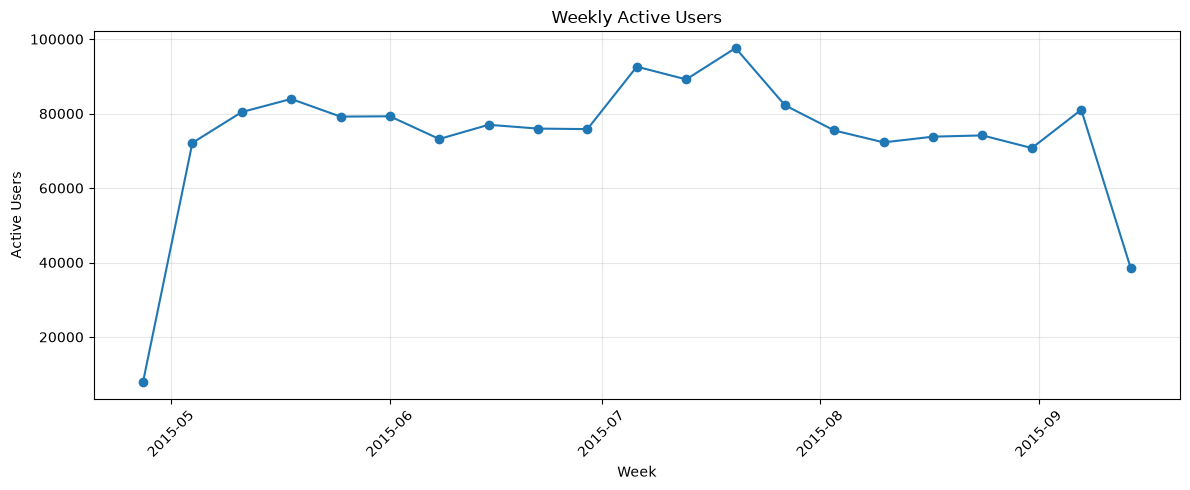

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    weekly_activity["week"],
    weekly_activity["active_users"],
    marker="o"
)

ax.set_title("Weekly Active Users")
ax.set_xlabel("Week")
ax.set_ylabel("Active Users")

ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_weekly_active_users.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [4]:
weekly_users = (
    events.groupby("week")["visitorid"]
    .apply(set)
    .sort_index()
)

weekly_retention = []

weeks = weekly_users.index

for i in range(len(weeks) - 1):
    current_users = weekly_users.iloc[i]
    next_users = weekly_users.iloc[i + 1]

    returned_users = len(current_users & next_users)

    retention = (
        returned_users / len(current_users)
        if len(current_users) > 0
        else np.nan
    )

    weekly_retention.append({
        "week": weeks[i],
        "active_users": len(current_users),
        "returned_users": returned_users,
        "retention_rate": retention
    })

weekly_retention = pd.DataFrame(weekly_retention)

weekly_retention

,week,active_users,returned_users,retention_rate
0,2015-04-27,7865,749,0.095232
1,2015-05-04,72138,3604,0.049960
2,2015-05-11,80409,4134,0.051412
3,2015-05-18,83929,3777,0.045002
4,2015-05-25,79192,3545,0.044765
5,2015-06-01,79273,3541,0.044668
6,2015-06-08,73177,3367,0.046012
7,2015-06-15,76996,3517,0.045678
8,2015-06-22,75970,3523,0.046374
9,2015-06-29,75834,3577,0.047169


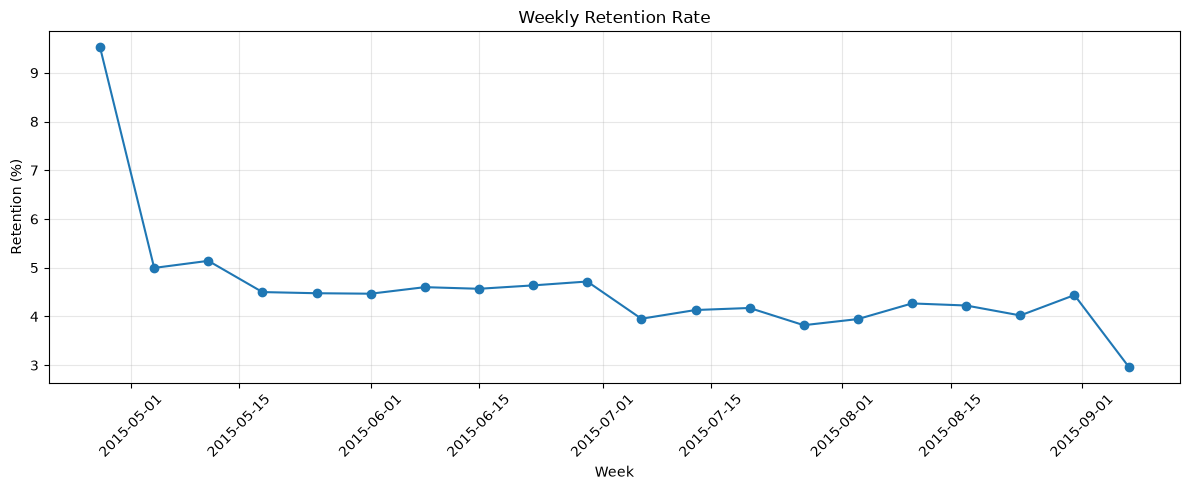

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    weekly_retention["week"],
    weekly_retention["retention_rate"] * 100,
    marker="o"
)

ax.set_title("Weekly Retention Rate")
ax.set_xlabel("Week")
ax.set_ylabel("Retention (%)")

ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_weekly_retention.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [6]:
observation_end = events["timestamp"].max()

last_activity = (
    events.groupby("visitorid")["timestamp"]
    .max()
    .rename("last_activity")
)

user_activity = last_activity.to_frame()

user_activity["days_since_last_activity"] = (
    observation_end - user_activity["last_activity"]
).dt.total_seconds() / 86400

user_activity["inactive_28_days"] = (
    user_activity["days_since_last_activity"] >= 28
)

user_activity.head()

,last_activity,days_since_last_activity,inactive_28_days
visitorid,,,
0,2015-09-11 20:55:17.175+00:00,6.253132,False
1,2015-08-13 17:46:06.444+00:00,35.384506,True
2,2015-08-07 18:20:57.845+00:00,41.360300,True
3,2015-08-01 07:10:35.296+00:00,47.825839,True
4,2015-09-15 21:24:27.167+00:00,2.232878,False


In [7]:
churn_summary = (
    user_activity["inactive_28_days"]
    .value_counts()
    .rename(index={
        True: "Inactive 28+ days",
        False: "Active within 28 days"
    })
    .to_frame("users")
)

churn_summary["share"] = (
    churn_summary["users"] / churn_summary["users"].sum()
)

churn_summary

,users,share
inactive_28_days,,
Inactive 28+ days,1129581,0.802499
Active within 28 days,277999,0.197501


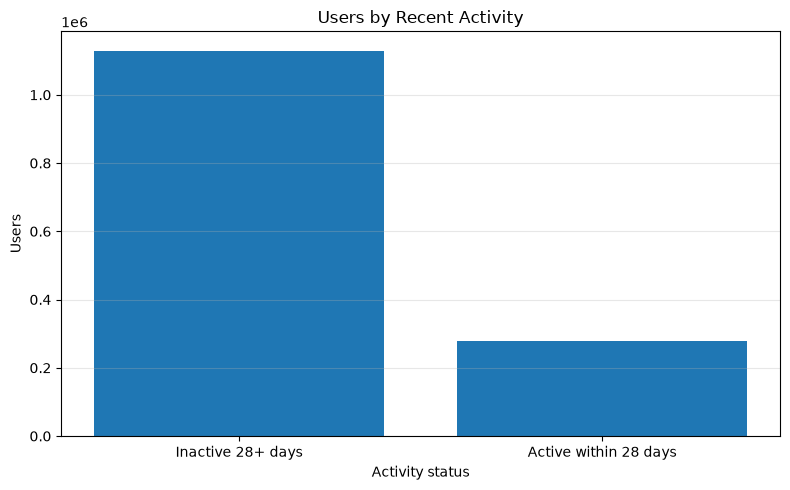

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    churn_summary.index,
    churn_summary["users"]
)

ax.set_title("Users by Recent Activity")
ax.set_xlabel("Activity status")
ax.set_ylabel("Users")

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_churn_status.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [9]:
SESSION_GAP = pd.Timedelta(minutes=30)

events["previous_timestamp"] = (
    events.groupby("visitorid")["timestamp"].shift(1)
)

events["time_since_previous"] = (
    events["timestamp"] - events["previous_timestamp"]
)

events["new_session"] = (
    events["previous_timestamp"].isna()
    | (events["time_since_previous"] > SESSION_GAP)
)

events["session_number"] = (
    events.groupby("visitorid")["new_session"]
    .cumsum()
)

events["session_id"] = (
    events["visitorid"].astype(str)
    + "_"
    + events["session_number"].astype(str)
)

events[[
    "visitorid",
    "timestamp",
    "event",
    "session_id",
    "new_session"
]].head(10)

,visitorid,timestamp,event,session_id,new_session
0,0,2015-09-11 20:49:49.439+00:00,view,0_1,True
1,0,2015-09-11 20:52:39.591+00:00,view,0_1,False
2,0,2015-09-11 20:55:17.175+00:00,view,0_1,False
3,1,2015-08-13 17:46:06.444+00:00,view,1_1,True
4,2,2015-08-07 17:51:44.567+00:00,view,2_1,True
5,2,2015-08-07 17:53:33.790+00:00,view,2_1,False
6,2,2015-08-07 17:56:52.664+00:00,view,2_1,False
7,2,2015-08-07 18:01:08.920+00:00,view,2_1,False
8,2,2015-08-07 18:08:25.669+00:00,view,2_1,False
9,2,2015-08-07 18:17:24.375+00:00,view,2_1,False


In [11]:
sessions = (
    events.groupby("session_id")
    .agg(
        visitorid=("visitorid", "first"),
        session_start=("timestamp", "min"),
        session_end=("timestamp", "max"),
        events_count=("event", "size"),
        views=("event", lambda x: (x == "view").sum()),
        addtocarts=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum())
    )
    .reset_index()
)

sessions["duration_minutes"] = (
    sessions["session_end"] - sessions["session_start"]
).dt.total_seconds() / 60

sessions.head()

,session_id,visitorid,session_start,session_end,events_count,views,addtocarts,transactions,duration_minutes
0,0_1,0,2015-09-11 20:49:49.439+00:00,2015-09-11 20:55:17.175+00:00,3,3,0,0,5.462267
1,1000000_1,1000000,2015-06-05 18:16:10.629+00:00,2015-06-05 18:16:10.629+00:00,1,1,0,0,0.000000
2,1000001_1,1000001,2015-07-07 18:12:14.953+00:00,2015-07-07 18:12:14.953+00:00,1,1,0,0,0.000000
3,1000001_2,1000001,2015-07-24 20:18:15.303+00:00,2015-07-24 20:35:57.029+00:00,3,3,0,0,17.695433
4,1000001_3,1000001,2015-07-29 20:38:29.170+00:00,2015-07-29 20:38:29.170+00:00,1,1,0,0,0.000000


In [12]:
session_summary = pd.DataFrame({
    "metric": [
        "Total sessions",
        "Unique users",
        "Average events per session",
        "Median events per session",
        "Average session duration (min)",
        "Median session duration (min)",
        "Sessions with one event"
    ],
    "value": [
        len(sessions),
        sessions["visitorid"].nunique(),
        sessions["events_count"].mean(),
        sessions["events_count"].median(),
        sessions["duration_minutes"].mean(),
        sessions["duration_minutes"].median(),
        (sessions["events_count"] == 1).sum()
    ]
})

session_summary

,metric,value
0,Total sessions,1.761675e+06
1,Unique users,1.407580e+06
2,Average events per session,1.564478e+00
3,Median events per session,1.000000e+00
4,Average session duration (min),1.754057e+00
5,Median session duration (min),0.000000e+00
6,Sessions with one event,1.378895e+06


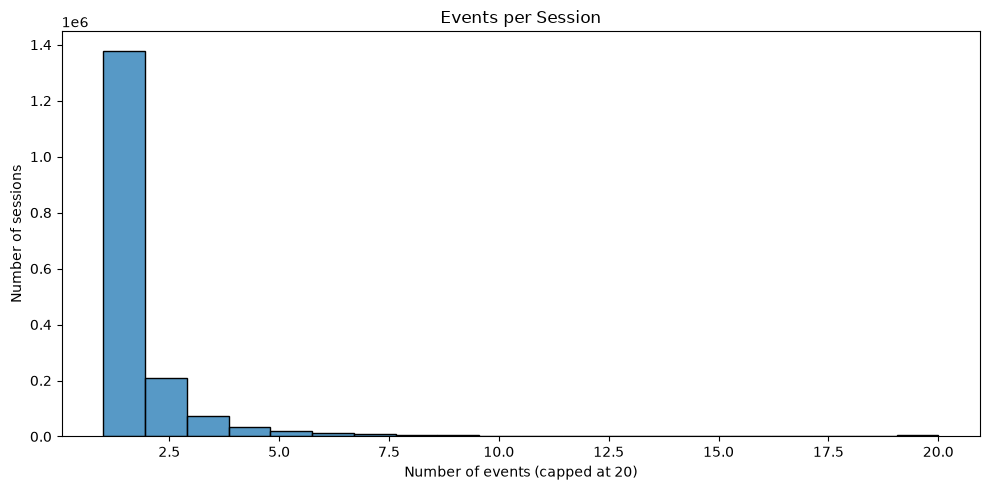

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    sessions["events_count"].clip(upper=20),
    bins=20,
    ax=ax
)

ax.set_title("Events per Session")
ax.set_xlabel("Number of events (capped at 20)")
ax.set_ylabel("Number of sessions")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_events_per_session.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

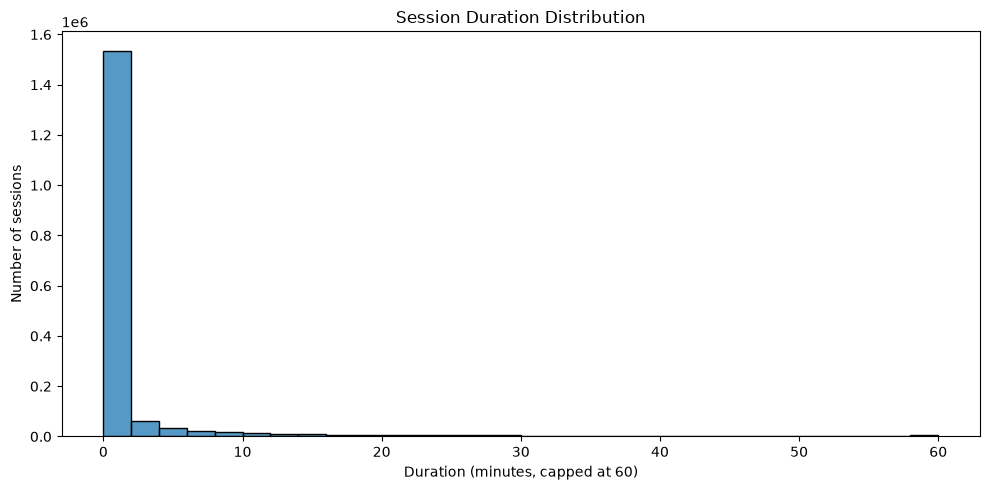

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    sessions["duration_minutes"].clip(upper=60),
    bins=30,
    ax=ax
)

ax.set_title("Session Duration Distribution")
ax.set_xlabel("Duration (minutes, capped at 60)")
ax.set_ylabel("Number of sessions")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_session_duration.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [15]:
sessions["session_type"] = np.select(
    [
        sessions["transactions"] > 0,
        sessions["addtocarts"] > 0,
        sessions["views"] > 0
    ],
    [
        "Purchase",
        "Add to cart",
        "View only"
    ],
    default="Other"
)

session_type_summary = (
    sessions.groupby("session_type")
    .agg(
        sessions=("session_id", "count"),
        avg_events=("events_count", "mean"),
        median_duration=("duration_minutes", "median")
    )
    .reset_index()
)

session_type_summary

,session_type,sessions,avg_events,median_duration
0,Add to cart,31992,4.699956,2.871267
1,Purchase,14297,9.344198,11.704317
2,View only,1715386,1.441160,0.000000


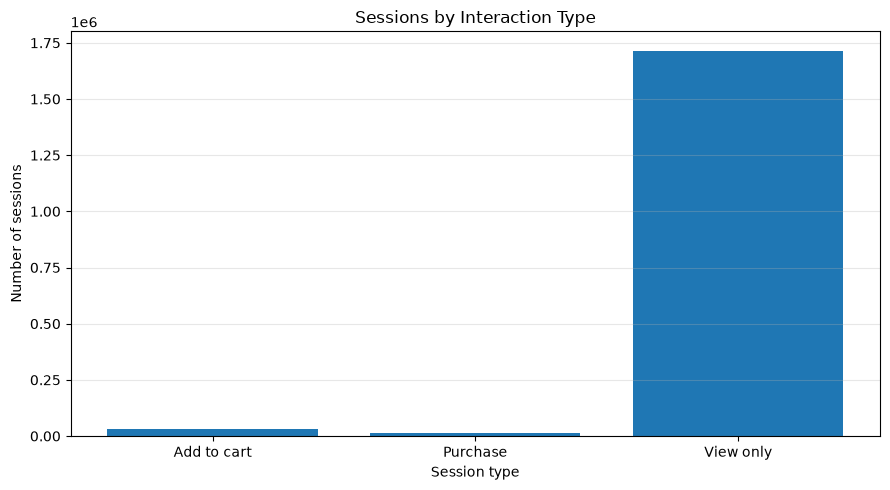

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    session_type_summary["session_type"],
    session_type_summary["sessions"]
)

ax.set_title("Sessions by Interaction Type")
ax.set_xlabel("Session type")
ax.set_ylabel("Number of sessions")

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_sessions_by_type.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [17]:
weekly_activity.to_csv(
    TABLES_DIR / "05_weekly_activity.csv",
    index=False
)

weekly_retention.to_csv(
    TABLES_DIR / "05_weekly_retention.csv",
    index=False
)

user_activity.to_csv(
    TABLES_DIR / "05_user_activity_churn.csv"
)

sessions.to_csv(
    TABLES_DIR / "05_sessions.csv",
    index=False
)

session_summary.to_csv(
    TABLES_DIR / "05_session_summary.csv",
    index=False
)

session_type_summary.to_csv(
    TABLES_DIR / "05_session_type_summary.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [18]:
multi_event_sessions = sessions[
    sessions["events_count"] > 1
]

multi_event_summary = multi_event_sessions[
    "duration_minutes"
].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
)

multi_event_summary

count    382780.000000
mean          8.072729
std          16.370586
min           0.000000
25%           0.950400
50%           2.981950
75%           9.405833
90%          21.427223
95%          29.135743
max         728.404133
Name: duration_minutes, dtype: float64

In [19]:
multi_event_summary.to_csv(
    TABLES_DIR / "05_multi_event_session_summary.csv",
    header=["value"]
)

print("Multi-event session statistics saved.")

Multi-event session statistics saved.


In [20]:
long_sessions = (
    sessions[sessions["duration_minutes"] > 30]
    .sort_values("duration_minutes", ascending=False)
)

long_sessions[
    [
        "session_id",
        "visitorid",
        "session_start",
        "session_end",
        "events_count",
        "duration_minutes"
    ]
].head(20)

,session_id,visitorid,session_start,session_end,events_count,duration_minutes
1107053,530033_1,530033,2015-06-04 14:55:58.341+00:00,2015-06-05 03:04:22.589+00:00,310,728.404133
1180956,582933_3,582933,2015-07-20 14:47:02.477+00:00,2015-07-21 02:53:26.032+00:00,191,726.392583
1092989,519839_2,519839,2015-07-07 15:05:32.826+00:00,2015-07-08 03:08:48.256+00:00,320,723.257167
209104,1150086_97,1150086,2015-07-25 15:05:26.576+00:00,2015-07-26 02:57:40.390+00:00,211,712.230233
1034929,477826_9,477826,2015-07-24 15:05:23.948+00:00,2015-07-25 02:52:11.399+00:00,150,706.790850
1225897,615132_9,615132,2015-08-07 15:10:15.108+00:00,2015-08-08 02:45:47.169+00:00,248,695.534350
887771,371606_3,371606,2015-06-27 15:31:04.427+00:00,2015-06-28 02:41:43.299+00:00,244,670.647867
1494419,807904_2,807904,2015-09-09 04:04:15.692+00:00,2015-09-09 15:12:55.246+00:00,49,668.659233
1107757,530559_107,530559,2015-07-25 15:28:17.422+00:00,2015-07-26 02:17:25.589+00:00,218,649.136117
1034921,477826_10,477826,2015-07-26 14:58:00.673+00:00,2015-07-27 01:32:31.241+00:00,156,634.509467


In [25]:
max_gap = (
    events.groupby("session_id")["timestamp"]
    .apply(lambda x: x.sort_values().diff().max())
    .max()
)

print("Maximum gap within a session:", max_gap)

KeyboardInterrupt: 

In [22]:
session_gaps = (
    events.groupby("session_id")["time_since_previous"]
    .max()
)

session_gap_summary = session_gaps.describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
)

session_gap_summary

count                      634541
mean       5 days 06:25:12.840997
std       14 days 18:18:59.227116
min               0 days 00:00:00
50%        0 days 01:02:28.518000
90%       14 days 22:56:31.949000
95%       34 days 03:26:04.892000
99%       79 days 01:51:11.768199
max      136 days 10:17:31.018000
Name: time_since_previous, dtype: object

In [23]:
within_session_gaps = events.loc[
    ~events["new_session"],
    "time_since_previous"
]

print(within_session_gaps.max())

0 days 00:30:00


In [24]:
long_session_summary = pd.Series({
    "sessions_over_30_min": (
        sessions["duration_minutes"] > 30
    ).sum(),

    "sessions_over_60_min": (
        sessions["duration_minutes"] > 60
    ).sum(),

    "sessions_over_120_min": (
        sessions["duration_minutes"] > 120
    ).sum(),

    "share_over_30_min": (
        sessions["duration_minutes"] > 30
    ).mean(),

    "share_over_60_min": (
        sessions["duration_minutes"] > 60
    ).mean()
})

long_session_summary

sessions_over_30_min     17372.000000
sessions_over_60_min      3953.000000
sessions_over_120_min     1033.000000
share_over_30_min            0.009861
share_over_60_min            0.002244
dtype: float64